# 05 · Previsões com o modelo vigente e comparação entre ciclos

O modelo vigente é carregado do armazenamento persistente **com** o pré-processamento e as features eleitas (tudo no mesmo `Pipeline`). As previsões são feitas para os clientes da **próxima campanha**: o lote que ainda não chegou ao pipeline e, portanto, não participou da escolha do modelo.

**Política de negócio:** o banco liga para os 20% de clientes com maior probabilidade de contratar.

In [1]:
import os, sys, warnings
from pathlib import Path
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore", category=UserWarning)
# Localiza a raiz do repositório e torna o pacote src importável
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.utils import carregar_config, configurar_mlflow, ler_contexto, atualizar_contexto, tags_ciclo, caminho, salvar_json
cfg = carregar_config()
pd.set_option("display.width", 160)

In [2]:
from src.promocao import carregar_vigente, HISTORICO_DECISOES
from src.ingestao import lote_pendente
from src.preprocessamento import limpar_e_criar_atributos, separar_xy
from src.modelagem import calcular_metricas

ctx = ler_contexto(cfg)
vigente, manifesto = carregar_vigente()
assert list(vigente.named_steps["selecao"].features) == manifesto["features"], "Modelo e manifesto divergentes"
print(f"Modelo vigente: {manifesto['algoritmo']} do ciclo {manifesto['cycle_id']} (run {manifesto['run_id']})")
print("Features:", manifesto["features"])

Modelo vigente: random_forest do ciclo c007-20261122-1830 (run 7df6fb03455f48bfaceffe43fc970a45)
Features: ['euribor3m', 'emp.var.rate', 'cons.price.idx', 'poutcome', 'month', 'contact', 'nr.employed', 'cons.conf.idx']


In [3]:
pendente = lote_pendente(cfg)
if pendente is not None:
    origem = f"próxima campanha (períodos {sorted(pendente['periodo'].unique())})"
    novos = limpar_e_criar_atributos(pendente, cfg)
else:
    origem = "teste reservado (fonte esgotada, sem campanha futura)"
    novos = pd.read_csv(caminho(cfg["dados"]["processed_dir"]) / "teste.csv")
X_novos, y_novos = separar_xy(novos, cfg)
proba = vigente.predict_proba(X_novos)[:, 1]

pct = cfg["negocio"]["percentual_contato"]
prev = novos[["registro_id", "periodo", "age", "job", "contact"]].copy()
prev["probabilidade_adesao"] = proba.round(4)
prev["ranking"] = prev["probabilidade_adesao"].rank(ascending=False, method="first").astype(int)
prev["ligar"] = prev["ranking"] <= int(len(prev) * pct)
prev = prev.sort_values("ranking")
print(f"Origem: {origem} | {len(prev)} clientes | {prev['ligar'].sum()} na lista de ligação")
display(prev.head(15))

Origem: teste reservado (fonte esgotada, sem campanha futura) | 6013 clientes | 1202 na lista de ligação


,registro_id,periodo,age,job,contact,probabilidade_adesao,ranking,ligar
5902,40381,2010-08,47,admin.,cellular,0.9846,1,True
5903,40387,2010-08,41,admin.,cellular,0.9841,2,True
5904,40389,2010-08,26,unemployed,cellular,0.9841,3,True
5905,40391,2010-08,26,unemployed,cellular,0.9841,4,True
5908,40447,2010-08,25,unemployed,cellular,0.9841,5,True
5898,40351,2010-08,31,student,cellular,0.9840,6,True
5916,40476,2010-08,42,technician,cellular,0.9840,7,True
5917,40484,2010-08,76,retired,cellular,0.9840,8,True
5918,40487,2010-08,33,admin.,cellular,0.9840,9,True
5896,40332,2010-08,25,student,cellular,0.9822,10,True


### O que teria acontecido? (os rótulos reais existem porque a campanha é histórica)

In [4]:
m = calcular_metricas(y_novos, proba, pct)
impacto = pd.DataFrame({
    "Ligar para todos": {"ligações": len(prev), "adesões": int(y_novos.sum()), "conversão": y_novos.mean()},
    f"Ligar para top {int(pct*100)}% (modelo)": {"ligações": int(prev["ligar"].sum()),
        "adesões": int(round(m["captura_top"] * y_novos.sum())), "conversão": m["conversao_top"]},
})
display(impacto.T.style.format({"conversão": "{:.1%}", "ligações": "{:,.0f}", "adesões": "{:,.0f}"}))
print(f"Com {int(pct*100)}% das ligações, o modelo captura {m['captura_top']:.0%} das adesões (lift {m['lift_top']:.1f}x).")

,ligações,adesões,conversão
Ligar para todos,"6,013",696,11.6%
Ligar para top 20% (modelo),"1,202",436,36.3%


Com 20% das ligações, o modelo captura 63% das adesões (lift 3.1x).


In [5]:
ev = caminho("evidencias") / ctx["cycle_id"]; ev.mkdir(parents=True, exist_ok=True)
prev.to_csv(ev / "previsoes.csv", index=False)
mlflow = configurar_mlflow(cfg)
with mlflow.start_run(run_name=f"{ctx['cycle_id']}_05_previsoes", tags=tags_ciclo(ctx, "05_previsoes")):
    mlflow.log_params({"origem_previsoes": origem, "modelo_vigente_cycle": manifesto["cycle_id"], "modelo_vigente_run": manifesto["run_id"]})
    mlflow.log_metrics({f"previsao_{k}": v for k, v in m.items()})
    mlflow.log_artifact(str(ev / "previsoes.csv"))

## Comparação entre ciclos

In [6]:
hist = pd.read_csv(caminho(HISTORICO_DECISOES))
metrica = cfg["avaliacao"]["metrica_principal"]
display(hist[["cycle_id", "gatilho", "data_version", "linhas_lote", "n_features", "cv_A", "cv_B", "vencedor",
              f"candidato_val_{metrica}", f"vigente_anterior_val_{metrica}", "decisao", "vigente_apos", "drift_alerta"]].round(4))

,cycle_id,gatilho,data_version,linhas_lote,n_features,cv_A,cv_B,vencedor,candidato_val_average_precision,vigente_anterior_val_average_precision,decisao,vigente_apos,drift_alerta
0,c001-20261116-2102,schedule,v001-44df464c,27680,8,0.0902,0.1004,B-random_forest,0.1045,NaN,PROMOVIDO,c001-20261116-2102-random_forest,False
1,c002-20261117-1951,schedule,v002-db4f8bd6,2750,8,0.1917,0.2058,B-random_forest,0.2043,0.1067,PROMOVIDO,c002-20261117-1951-random_forest,True
2,c003-20261118-1924,schedule,v003-31eeff6c,6687,8,0.2341,0.2348,B-random_forest,0.2555,0.2224,PROMOVIDO,c003-20261118-1924-random_forest,True
3,c004-20261119-1929,schedule,v004-ce2b8d77,1484,8,0.2982,0.3015,B-random_forest,0.3209,0.2818,PROMOVIDO,c004-20261119-1929-random_forest,True
4,c005-20261120-1906,schedule,v005-0c33f7d6,793,8,0.3480,0.3615,B-random_forest,0.3628,0.3470,PROMOVIDO,c005-20261120-1906-random_forest,True
5,c006-20261121-1758,schedule,v006-c063ab96,615,8,0.3847,0.4016,B-random_forest,0.4154,0.3901,PROMOVIDO,c006-20261121-1758-random_forest,True
6,c007-20261122-1830,schedule,v007-9acfd71d,847,8,0.4307,0.4459,B-random_forest,0.4584,0.4506,PROMOVIDO,c007-20261122-1830-random_forest,True
7,c008-20261123-2238,schedule,v008-7803f4a3,332,8,0.4383,0.4562,B-random_forest,0.4632,0.4666,MANTIDO,c007-20261122-1830-random_forest,True
8,c009-20261124-2111,schedule,v008-7803f4a3,0,8,0.4383,0.4562,B-random_forest,0.4632,0.4666,MANTIDO,c007-20261122-1830-random_forest,False


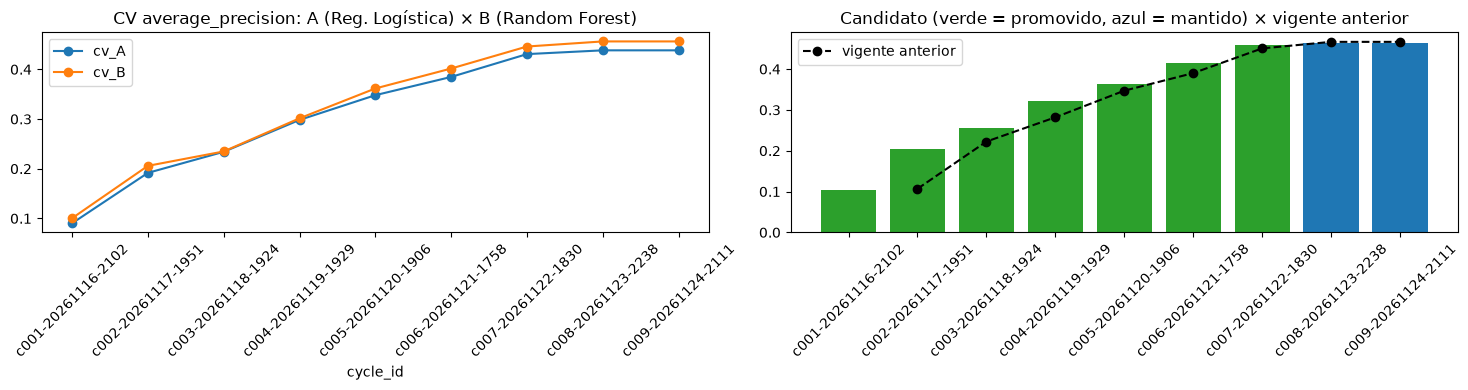

Ciclos em que o conjunto de features mudou: ['c001-20261116-2102', 'c002-20261117-1951', 'c003-20261118-1924', 'c004-20261119-1929', 'c005-20261120-1906', 'c006-20261121-1758', 'c007-20261122-1830', 'c008-20261123-2238']


In [7]:
if len(hist) > 1:
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    hist.plot(x="cycle_id", y=["cv_A", "cv_B"], marker="o", ax=ax[0], title=f"CV {metrica}: A (Reg. Logística) × B (Random Forest)")
    cores = hist["decisao"].map({"PROMOVIDO": "#2ca02c", "MANTIDO": "#1f77b4", "REJEITADO": "#d62728"})
    ax[1].bar(hist["cycle_id"], hist[f"candidato_val_{metrica}"], color=cores)
    ax[1].plot(hist["cycle_id"], hist[f"vigente_anterior_val_{metrica}"], "ko--", label="vigente anterior")
    ax[1].set_title("Candidato (verde = promovido, azul = mantido) × vigente anterior"); ax[1].legend()
    for a in ax: a.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()

    mudou = hist["features_eleitas"].ne(hist["features_eleitas"].shift())
    print("Ciclos em que o conjunto de features mudou:", hist.loc[mudou, "cycle_id"].tolist())

In [8]:
# Histórico consultável no MLflow: todos os runs de todos os ciclos
mlflow = configurar_mlflow(cfg)
runs = mlflow.search_runs(experiment_names=[cfg["mlflow"]["experimento"]], order_by=["start_time ASC"])
cols = [c for c in ["tags.cycle_id", "tags.etapa", "tags.data_version", "tags.gatilho", "params.algoritmo",
                    f"metrics.cv_{metrica}_media", "params.decisao", "run_id"] if c in runs.columns]
display(runs[cols].tail(20))

,tags.cycle_id,tags.etapa,tags.data_version,tags.gatilho,params.algoritmo,metrics.cv_average_precision_media,params.decisao,run_id
34,c006-20261121-1758,04_promocao,v006-c063ab96,schedule,NaN,NaN,PROMOVIDO,2cc180490c5d4a33b896c354b7f1a560
35,c006-20261121-1758,05_previsoes,v006-c063ab96,schedule,NaN,NaN,NaN,e257f71ee4b04c2683d556a2fe48d131
36,c007-20261122-1830,01_etl,v007-9acfd71d,schedule,NaN,NaN,NaN,4425ab0dc145445da465cbda5baf50b2
37,c007-20261122-1830,02_votacao,v007-9acfd71d,schedule,NaN,NaN,NaN,39e56076c682408088f64d4f24ff8447
38,c007-20261122-1830,03_treino,v007-9acfd71d,schedule,regressao_logistica,0.430669,NaN,ef02c1adc175476ab9d90ca39bb29080
39,c007-20261122-1830,03_treino,v007-9acfd71d,schedule,random_forest,0.445941,NaN,7df6fb03455f48bfaceffe43fc970a45
40,c007-20261122-1830,04_promocao,v007-9acfd71d,schedule,NaN,NaN,PROMOVIDO,b210f28f4c3844069a47a44c13ab262e
41,c007-20261122-1830,05_previsoes,v007-9acfd71d,schedule,NaN,NaN,NaN,9dd30319e1a24ae3a3d98919b74ef57c
42,c008-20261123-2238,01_etl,v008-7803f4a3,schedule,NaN,NaN,NaN,c4abeb2e572b47b8b86e60edeedf1425
43,c008-20261123-2238,02_votacao,v008-7803f4a3,schedule,NaN,NaN,NaN,b64d2f5649564ed4aeffcc17dbca1e1e
